# Exploracion general de produccion y paradas

**Pregunta:** durante el tiempo en que estaba previsto producir, donde se pierde
capacidad y que evidencia justifica una investigacion?

El analisis admite otras lineas y operaciones con el mismo contrato de datos diarios.
Las rutas, nombres de columnas, unidades, objetivos y calendario son configurables.
No se codifican nombres de maquinas ni fechas festivas. La configuracion puede tener
operaciones paralelas: su orden no sustituye a un grafo de conexiones.

Separaremos hechos observados, problemas de calidad e hipotesis. Un dia sin actividad
no demuestra que sea festivo; una maquina parada no demuestra que estuviera inactiva
por planificacion. Los datos originales se conservan sin cambios.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import display

# Mostrar las figuras dentro del notebook, incluso si el kernel usaba Agg.
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')

ROOT = Path.cwd()
if not (ROOT / 'data').exists() and (ROOT.parent / 'data').exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / 'data' / 'datos_hackaton.csv'
CONFIG_PATH = ROOT / 'data' / 'config_hackaton.csv'
CALENDAR_PATH = None  # CSV opcional, definido en la siguiente seccion
CSV_OPTIONS = {'sep': ',', 'decimal': '.', 'encoding': 'utf-8-sig'}
COLUMN_MAP = {}  # Ejemplo: {'Machine': 'Operacion', 'Day': 'Jour'}
CONFIG_COLUMN_MAP = {}
TIME_UNIT = 'hours'  # 'hours', 'minutes' o 'seconds'; confirmar con el propietario
REFERENCE_HOURS = 22.0  # referencia configurable, NO denominador obligatorio
TIME_TOLERANCE_HOURS = 0.10  # tolerancia exploratoria, no regla de correccion
AVAILABILITY_TARGET = 90.0
CYCLE_TARGET_CMIN = 80.0
STOP_RATE_BASE = 1000  # Fpm por mil segun presentacion/README; usar 100 si se acuerda
MICROSTOP_MEAN_SECONDS = 60.0  # hipotesis exploratoria, no umbral validado
TOP_N = 10
DAY_KEYS = ['Linea', 'Year', 'Week', 'Jour']
JOIN_KEYS = ['Linea', 'Operacion']
ROW_KEYS = DAY_KEYS + ['Operacion']
TIMES = ['TBF', 'TAP', 'DES', 'SAT']
COUNTERS = ['NAP', 'NPR']
VALUES = TIMES + COUNTERS
FLAGS = ['production_without_runtime', 'runtime_without_production',
         'stops_without_own_time', 'own_time_without_stops']
COLORS = {'TBF': '#2a9d8f', 'TAP': '#e76f51', 'DES': '#457b9d', 'SAT': '#b39ddb'}
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.figsize': (11, 5), 'axes.spines.top': False, 'axes.spines.right': False})
raw_data = pd.read_csv(DATA_PATH, **CSV_OPTIONS).rename(columns=lambda col: col.strip()).rename(columns=COLUMN_MAP)
raw_config = pd.read_csv(CONFIG_PATH, **CSV_OPTIONS).rename(columns=lambda col: col.strip()).rename(columns=CONFIG_COLUMN_MAP)
print(f'Entrada: {len(raw_data)} registros; {len(raw_config)} operaciones configuradas.')

Entrada: 1820 registros; 91 operaciones configuradas.


## 1. Contrato, duplicados y calidad

Se espera una fila por **linea, operacion, anio, semana y dia**. Otros formatos
(por turno o por evento) requieren adaptar la clave antes de usar el analisis.

- Normalizamos espacios en cabeceras e identificadores; no cambiamos guiones ni nombres.
- Eliminamos solo copias completamente identicas y contamos cuantas eran.
- Si quedan varias filas para una misma clave diaria, las apartamos para revision:
  no sabemos si son correcciones, turnos o duplicados y no las sumamos arbitrariamente.
- Apartamos registros incompletos, negativos, no finitos o con contadores no enteros.
- Comprobamos la union con configuracion. Repetir un numero de orden puede representar
  paralelismo y no se elimina como duplicado.

Los registros apartados quedan disponibles en `quarantine`; las incidencias en `audit`.
Apartar no significa corregir ni asumir que el resto del periodo esta completo.

El detalle de cada senal muestra **linea, operacion, orden, anio, semana y dia**,
con todos los tiempos (en horas) y contadores que permiten comprobarla. Se muestran
todos los registros, sin limitarse a los primeros. Una fila puede aparecer en varias
senales. Este detalle es anterior al tratamiento del calendario del punto 2.


In [2]:
def prepare_data(source, configuration, time_unit):
    data, config = source.copy(), configuration.copy()
    data.columns = data.columns.str.strip()
    config.columns = config.columns.str.strip()
    if data.columns.duplicated().any() or config.columns.duplicated().any():
        raise ValueError('Hay nombres de columnas repetidos despues de normalizar.')
    for frame, required in [(data, ROW_KEYS + VALUES), (config, JOIN_KEYS + ['Orden_OP'])]:
        missing = set(required) - set(frame.columns)
        if missing:
            raise ValueError(f'Faltan columnas requeridas: {sorted(missing)}')
        for col in JOIN_KEYS:
            frame[col] = frame[col].astype('string').str.strip().replace('', pd.NA)
    duplicate_copies = data.duplicated().sum()
    data = data.drop_duplicates().copy()
    numeric_cols = ['Year', 'Week', 'Jour'] + VALUES
    for col in numeric_cols:
        data[col] = pd.to_numeric(data[col], errors='coerce')
    config['Orden_OP'] = pd.to_numeric(config['Orden_OP'], errors='coerce')
    if config[JOIN_KEYS].isna().any().any() or not np.isfinite(config['Orden_OP']).all():
        raise ValueError('Configuracion incompleta o con orden no numerico.')
    if config.duplicated(JOIN_KEYS).any():
        raise ValueError('Configuracion ambigua: claves Linea + Operacion repetidas.')
    factors = {'hours': 1, 'minutes': 1/60, 'seconds': 1/3600}
    if time_unit not in factors:
        raise ValueError('TIME_UNIT debe ser hours, minutes o seconds.')
    bad_key = data[ROW_KEYS].isna().any(axis=1)
    date_invalid = (data[['Year', 'Week', 'Jour']].mod(1).ne(0).any(axis=1)
                    | ~data['Year'].between(1, 9999) | ~data['Week'].between(1, 53)
                    | ~data['Jour'].between(1, 7))
    bad_numeric = ~np.isfinite(data[numeric_cols]).all(axis=1) | data[VALUES].lt(0).any(axis=1)
    bad_counter = data[COUNTERS].mod(1).ne(0).any(axis=1)
    repeated_key = data.duplicated(ROW_KEYS, keep=False)
    known_keys = pd.MultiIndex.from_frame(config[JOIN_KEYS])
    unknown = ~pd.MultiIndex.from_frame(data[JOIN_KEYS]).isin(known_keys)
    issues = pd.DataFrame({'invalid_key_or_day': bad_key | date_invalid,
                           'invalid_numeric': bad_numeric | bad_counter,
                           'conflicting_daily_key': repeated_key,
                           'operation_not_configured': unknown}, index=data.index)
    excluded = issues.any(axis=1)
    quarantine = data.loc[excluded].join(issues.add_prefix('issue_'))
    clean = data.loc[~excluded].copy()
    clean[TIMES] = clean[TIMES] * factors[time_unit]
    clean = clean.merge(config[JOIN_KEYS + ['Orden_OP']], on=JOIN_KEYS, validate='many_to_one')
    clean['production_without_runtime'] = clean.NPR.gt(0) & clean.TBF.eq(0)
    clean['runtime_without_production'] = clean.TBF.gt(0) & clean.NPR.eq(0)
    clean['stops_without_own_time'] = clean.NAP.gt(0) & clean.TAP.eq(0)
    clean['own_time_without_stops'] = clean.TAP.gt(0) & clean.NAP.eq(0)
    audit = pd.Series({'input_rows': len(source), 'identical_copies_removed': int(duplicate_copies),
                       'quarantined_rows': int(excluded.sum()), 'usable_rows': len(clean),
                       **issues.sum().astype(int).to_dict()}, name='Registros')
    return clean, config, quarantine, audit

clean, config, quarantine, audit = prepare_data(raw_data, raw_config, TIME_UNIT)
display(audit.to_frame())
if clean.empty:
    raise ValueError('No quedan registros utilizables: revisar quarantine antes de continuar.')
display(clean[FLAGS].sum().rename('Registros con senal de revision').to_frame())

,Registros
input_rows,1820
identical_copies_removed,0
quarantined_rows,0
usable_rows,1820
invalid_key_or_day,0
invalid_numeric,0
conflicting_daily_key,0
operation_not_configured,0


,Registros con senal de revision
production_without_runtime,4
runtime_without_production,65
stops_without_own_time,16
own_time_without_stops,364


In [3]:
# Localizacion exacta de todos los registros que activan cada senal.
REVIEW_LABELS = {
    'production_without_runtime': 'Produccion sin tiempo de funcionamiento (NPR > 0 y TBF = 0)',
    'runtime_without_production': 'Funcionamiento sin produccion (TBF > 0 y NPR = 0)',
    'stops_without_own_time': 'Paradas propias sin tiempo registrado (NAP > 0 y TAP = 0)',
    'own_time_without_stops': 'Tiempo de parada propia sin paradas contadas (TAP > 0 y NAP = 0)',
}
REVIEW_COLUMNS = ['Linea', 'Operacion', 'Orden_OP', 'Year', 'Week', 'Jour'] + VALUES
REVIEW_ORDER = ['Linea', 'Year', 'Week', 'Jour', 'Orden_OP', 'Operacion']
review_records = {}
for signal in FLAGS:
    detail = (clean.loc[clean[signal], REVIEW_COLUMNS]
              .sort_values(REVIEW_ORDER).reset_index(drop=True))
    review_records[signal] = detail
    print(f'{signal}: {REVIEW_LABELS[signal]}')
    print(f'Registros: {len(detail)} | Tiempos en horas; Year = anio, Week = semana, Jour = dia.')
    if detail.empty:
        print('No se han encontrado registros con esta senal.')
    else:
        # Mostrar todas las filas; el resumen anterior sigue disponible para consultar cantidades.
        with pd.option_context('display.max_rows', None, 'display.max_columns', None):
            display(detail)

production_without_runtime: Produccion sin tiempo de funcionamiento (NPR > 0 y TBF = 0)
Registros: 4 | Tiempos en horas; Year = anio, Week = semana, Jour = dia.


,Linea,Operacion,Orden_OP,Year,Week,Jour,TBF,TAP,DES,SAT,NAP,NPR
0,VLL_MONTAJE_L5,Ma_BM2_2,88,2026,42,4,0.0,22.00,0.0,0.0,12,1509
1,VLL_MONTAJE_L5,Ma_BM2_2,88,2026,43,3,0.0,22.00,0.0,0.0,12,1541
2,VLL_MONTAJE_L5,Ma_BM2_2,88,2026,43,4,0.0,22.01,0.0,0.0,12,1513
3,VLL_MONTAJE_L5,Ma_BM2_2,88,2026,43,5,0.0,22.00,0.0,0.0,12,1531


runtime_without_production: Funcionamiento sin produccion (TBF > 0 y NPR = 0)
Registros: 65 | Tiempos en horas; Year = anio, Week = semana, Jour = dia.


,Linea,Operacion,Orden_OP,Year,Week,Jour,TBF,TAP,DES,SAT,NAP,NPR
0,VLL_MONTAJE_L5,Ma_BM1_2,86,2026,40,2,22.00,0.00,0.00,0.00,0,0
1,VLL_MONTAJE_L5,ManBM2_1,87,2026,40,2,0.29,21.72,0.00,0.00,13,0
2,VLL_MONTAJE_L5,Ma_VES_0,89,2026,40,2,22.00,0.00,0.00,0.00,0,0
3,VLL_MONTAJE_L5,Ma_VESRE,90,2026,40,2,22.00,0.00,0.00,0.00,1,0
4,VLL_MONTAJE_L5,ST-0295,25,2026,40,3,18.86,0.07,0.67,2.40,2,0
5,VLL_MONTAJE_L5,Ma_BM1_2,86,2026,40,3,22.00,0.00,0.00,0.00,0,0
6,VLL_MONTAJE_L5,ManBM2_1,87,2026,40,3,0.34,21.67,0.00,0.00,13,0
7,VLL_MONTAJE_L5,Ma_VES_0,89,2026,40,3,22.00,0.00,0.00,0.00,0,0
8,VLL_MONTAJE_L5,Ma_VESRE,90,2026,40,3,22.01,0.00,0.00,0.00,0,0
9,VLL_MONTAJE_L5,Ma_BM1_2,86,2026,40,4,21.98,0.03,0.00,0.00,2,0


stops_without_own_time: Paradas propias sin tiempo registrado (NAP > 0 y TAP = 0)
Registros: 16 | Tiempos en horas; Year = anio, Week = semana, Jour = dia.


,Linea,Operacion,Orden_OP,Year,Week,Jour,TBF,TAP,DES,SAT,NAP,NPR
0,VLL_MONTAJE_L5,Ma_VESRE,90,2026,40,2,22.00,0.0,0.00,0.00,1,0
1,VLL_MONTAJE_L5,ST-0240,16,2026,40,4,19.55,0.0,0.02,2.43,1,1497
2,VLL_MONTAJE_L5,Ma_BM2_2,88,2026,40,5,8.70,0.0,13.29,0.00,1051,1459
3,VLL_MONTAJE_L5,Ma_VES_0,89,2026,41,1,22.01,0.0,0.00,0.00,2,0
4,VLL_MONTAJE_L5,PM_2310,68,2026,41,3,19.70,0.0,1.49,0.00,3,1550
5,VLL_MONTAJE_L5,ManutPul,34,2026,42,2,13.83,0.0,8.07,0.10,1261,1539
6,VLL_MONTAJE_L5,PM_2310,68,2026,42,2,18.72,0.0,2.21,0.00,2,1533
7,VLL_MONTAJE_L5,Ma_VES_0,89,2026,42,2,22.00,0.0,0.00,0.00,1,0
8,VLL_MONTAJE_L5,ManutPul,34,2026,42,3,13.43,0.0,8.04,0.52,1221,1510
9,VLL_MONTAJE_L5,PM_2310,68,2026,42,3,19.11,0.0,1.82,0.00,1,1516


own_time_without_stops: Tiempo de parada propia sin paradas contadas (TAP > 0 y NAP = 0)
Registros: 364 | Tiempos en horas; Year = anio, Week = semana, Jour = dia.


,Linea,Operacion,Orden_OP,Year,Week,Jour,TBF,TAP,DES,SAT,NAP,NPR
0,VLL_MONTAJE_L5,ST_0015,1,2026,40,1,0.0,22.0,0.0,0.0,0,0
1,VLL_MONTAJE_L5,ST_0020,2,2026,40,1,0.0,22.0,0.0,0.0,0,0
2,VLL_MONTAJE_L5,ST_0030,3,2026,40,1,0.0,22.0,0.0,0.0,0,0
3,VLL_MONTAJE_L5,ST_0040,4,2026,40,1,0.0,22.0,0.0,0.0,0,0
4,VLL_MONTAJE_L5,ST-0050,5,2026,40,1,0.0,22.0,0.0,0.0,0,0
5,VLL_MONTAJE_L5,PM_0090,6,2026,40,1,0.0,22.0,0.0,0.0,0,0
6,VLL_MONTAJE_L5,ST_0095,7,2026,40,1,0.0,22.0,0.0,0.0,0,0
7,VLL_MONTAJE_L5,ST_0100,8,2026,40,1,0.0,22.0,0.0,0.0,0,0
8,VLL_MONTAJE_L5,PM_0110,9,2026,40,1,0.0,22.0,0.0,0.0,0,0
9,VLL_MONTAJE_L5,ST_0115,10,2026,40,1,0.0,22.0,0.0,0.0,0,0


## 2. Calendario, cobertura y dias sin actividad

El calendario de fabrica es preferible al calendario de festivos civiles: puede
haber turnos especiales, puentes y cierres. CSV opcional con estas columnas:
`Linea, Year, Week, Jour, Planned_Production` (0 o 1), y `Planned_Hours` opcional.
Cada clave diaria debe ser unica. Un calendario parcial deja el resto como desconocido.
No convertimos `Jour` a una fecha hasta confirmar que usa dias ISO de la semana.

Sin calendario, un dia con cobertura completa, TBF cero y NPR cero en toda la linea
se marca **sin actividad, pendiente de confirmar**. No se etiqueta como festivo.
Si el calendario indica produccion prevista, ese dia se conserva aunque todo se pare.
Si faltan operaciones, tampoco afirmamos que la linea entera estuviese cerrada.

In [4]:
def classify_days(clean, config, calendar=None):
    days = clean.groupby(DAY_KEYS, as_index=False).agg(
        observed_operations=('Operacion', 'nunique'),
        all_zero_runtime=('TBF', lambda s: s.eq(0).all()),
        all_zero_output=('NPR', lambda s: s.eq(0).all()))
    expected = config.groupby('Linea').size().rename('expected_operations')
    days = days.join(expected, on='Linea')
    days['complete_coverage'] = days.observed_operations.eq(days.expected_operations)
    days['no_activity_signal'] = days.complete_coverage & days.all_zero_runtime & days.all_zero_output
    if calendar is not None:
        calendar = calendar.copy()
        calendar.columns = calendar.columns.str.strip()
        if not set(DAY_KEYS + ['Planned_Production']).issubset(calendar.columns):
            raise ValueError('Calendario sin columnas requeridas.')
        calendar['Linea'] = calendar['Linea'].astype('string').str.strip()
        for col in ['Year', 'Week', 'Jour', 'Planned_Production']:
            calendar[col] = pd.to_numeric(calendar[col], errors='coerce')
        if calendar[DAY_KEYS].isna().any().any() or calendar.duplicated(DAY_KEYS).any():
            raise ValueError('Calendario con claves incompletas o duplicadas.')
        if not calendar.Planned_Production.isin([0, 1]).all():
            raise ValueError('Planned_Production debe ser 0 o 1.')
        if 'Planned_Hours' not in calendar:
            calendar['Planned_Hours'] = np.nan
        else:
            calendar['Planned_Hours'] = pd.to_numeric(calendar['Planned_Hours'], errors='raise')
            hours = calendar.Planned_Hours.dropna()
            if not np.isfinite(hours).all() or hours.lt(0).any():
                raise ValueError('Planned_Hours debe ser no negativo y finito.')
        days = days.merge(calendar[DAY_KEYS + ['Planned_Production', 'Planned_Hours']],
                          on=DAY_KEYS, how='left', validate='one_to_one')
    else:
        days['Planned_Production'] = np.nan
        days['Planned_Hours'] = np.nan
    days['day_status'] = np.select(
        [days.Planned_Production.eq(0), days.Planned_Production.eq(1), days.no_activity_signal],
        ['cierre_confirmado', 'produccion_planificada', 'sin_actividad_por_confirmar'],
        default='planificacion_desconocida')
    days['reference_hours'] = days.Planned_Hours.fillna(REFERENCE_HOURS)
    return days

calendar = None if CALENDAR_PATH is None else pd.read_csv(CALENDAR_PATH, **CSV_OPTIONS)
if calendar is not None:
    calendar.columns = calendar.columns.str.strip()
    calendar['Linea'] = calendar['Linea'].astype('string').str.strip()
    for column in ['Year', 'Week', 'Jour']:
        calendar[column] = pd.to_numeric(calendar[column], errors='raise')
days = classify_days(clean, config, calendar)
print('Cobertura por estado del dia:')
display(days.groupby(['Linea', 'day_status']).size().rename('Dias').to_frame())
print('Dias sin actividad que necesitan confirmacion:')
display(days.loc[days.day_status.eq('sin_actividad_por_confirmar'), DAY_KEYS + ['observed_operations']])
print('Dias con cobertura incompleta; los registros apartados tambien pueden explicarlo:')
display(days.loc[~days.complete_coverage, DAY_KEYS + ['observed_operations', 'expected_operations']])
# Comparar tambien con claves existentes solo en los registros originales, no utilizables.
raw_day_keys = raw_data[DAY_KEYS].copy()
raw_day_keys['Linea'] = raw_day_keys['Linea'].astype('string').str.strip()
for column in ['Year', 'Week', 'Jour']:
    raw_day_keys[column] = pd.to_numeric(raw_day_keys[column], errors='coerce')
observed_raw_days = raw_day_keys.dropna().drop_duplicates()
unusable_days = observed_raw_days.merge(days[DAY_KEYS], on=DAY_KEYS, how='left', indicator=True)
print('Dias presentes en origen sin ningun registro utilizable:')
display(unusable_days.loc[unusable_days['_merge'].eq('left_only'), DAY_KEYS])
if calendar is not None:
    calendar_without_data = calendar.merge(observed_raw_days, on=DAY_KEYS, how='left', indicator=True)
    print('Dias del calendario sin registros: no se interpretan como cero produccion.')
    display(calendar_without_data.loc[calendar_without_data['_merge'].eq('left_only'), DAY_KEYS])
records = clean.merge(days, on=DAY_KEYS, validate='many_to_one')
records['recorded_hours'] = records[TIMES].sum(axis=1)
records['time_reference_mismatch'] = records.recorded_hours.sub(records.reference_hours).abs().gt(TIME_TOLERANCE_HOURS)
print('Las discrepancias con las horas de referencia se senalan, no se fuerzan ni se borran.')

Cobertura por estado del dia:


Dias
Linea          day_status                       
VLL_MONTAJE_L5 planificacion_desconocida      16
               sin_actividad_por_confirmar     4

Dias sin actividad que necesitan confirmacion:


,Linea,Year,Week,Jour,observed_operations
0,VLL_MONTAJE_L5,2026,40,1,91
9,VLL_MONTAJE_L5,2026,41,5,91
10,VLL_MONTAJE_L5,2026,42,1,91
14,VLL_MONTAJE_L5,2026,42,5,91


Dias con cobertura incompleta; los registros apartados tambien pueden explicarlo:


,Linea,Year,Week,Jour,observed_operations,expected_operations


Dias presentes en origen sin ningun registro utilizable:


,Linea,Year,Week,Jour


Las discrepancias con las horas de referencia se senalan, no se fuerzan ni se borran.


## 3. Sensibilidad: cuanto cambia el resultado al tratar los cierres

Comparamos tres escenarios. No mezclamos sus resultados:

1. Todos los registros utilizables: muestra el sesgo que puede causar el calendario.
2. Sin cierres confirmados: excluye solo lo que consta en planificacion.
3. Escenario exploratorio sin dias sospechosos de cierre: excluye tambien los dias
   completos sin actividad y sin calendario. Sus resultados son provisionales.

El escenario 3 se usa para explorar graficas y prioridades. No sustituye la confirmacion
del calendario. Nunca eliminamos una fila solo porque una maquina tenga TBF cero.

In [5]:
def add_metrics(frame):
    result = frame.copy()
    result['TAI'] = result.DES + result.SAT
    result['TR'] = result[TIMES].sum(axis=1)
    result['availability_pct'] = 100 * result.TBF.div((result.TBF + result.TAP).where(lambda s: s.gt(0)))
    result['own_stop_rate'] = STOP_RATE_BASE * result.NAP.div(result.NPR.where(lambda s: s.gt(0)))
    result['cycle_cmin'] = 6000 * result.TBF.div(result.NPR.where(lambda s: s.gt(0)))
    result.loc[result.production_without_runtime.gt(0) | result.TBF.le(0), 'cycle_cmin'] = np.nan
    result['mean_stop_seconds'] = 3600 * result.TAP.div(result.NAP.where(lambda s: s.gt(0)))
    result.loc[result.stops_without_own_time.gt(0) | result.own_time_without_stops.gt(0), 'mean_stop_seconds'] = np.nan
    result['induced_pct'] = 100 * result.TAI.div(result.TR.where(lambda s: s.gt(0)))
    return result

OP_KEYS = JOIN_KEYS + ['Orden_OP']
SUM_COLUMNS = VALUES + FLAGS + ['time_reference_mismatch']
def aggregate(frame, keys):
    result = frame.groupby(keys, as_index=False)[SUM_COLUMNS].sum()
    counts = frame.groupby(keys).size().rename('observed_days').reset_index()
    return add_metrics(result.merge(counts, on=keys, validate='one_to_one'))

not_closed = ~records.day_status.eq('cierre_confirmado')
exploratory_mask = not_closed & ~records.day_status.eq('sin_actividad_por_confirmar')
scenarios = {'Todos los registros': records,
             'Sin cierres confirmados': records.loc[not_closed],
             'Sin cierres sospechosos (provisional)': records.loc[exploratory_mask]}
scenario_rows = []
for scenario_name, frame in scenarios.items():
    summary = aggregate(frame, OP_KEYS)
    for line, line_summary in summary.groupby('Linea'):
        eligible = line_summary.NPR.gt(0) & line_summary.TBF.gt(0) & line_summary.production_without_runtime.eq(0)
        scenario_rows.append({'Escenario': scenario_name, 'Linea': line,
                             'Dias': len(frame.loc[frame.Linea.eq(line), DAY_KEYS].drop_duplicates()),
                             'Operaciones_comparables': int(eligible.sum()),
                             'Bajo_objetivo_disponibilidad': int((eligible & line_summary.availability_pct.lt(AVAILABILITY_TARGET)).sum())})
scenario_comparison = pd.DataFrame(scenario_rows)
display(scenario_comparison)
working = records.loc[exploratory_mask].copy()
if working.empty:
    print('No hay dias comparables en el escenario exploratorio: no emitir prioridades.')

,Escenario,Linea,Dias,Operaciones_comparables,Bajo_objetivo_disponibilidad
0,Todos los registros,VLL_MONTAJE_L5,20,84,84
1,Sin cierres confirmados,VLL_MONTAJE_L5,20,84,84
2,Sin cierres sospechosos (provisional),VLL_MONTAJE_L5,16,84,5


## 4. Indicadores comparables y cobertura por operacion

Sumamos tiempos y contadores antes de calcular ratios. No promediamos porcentajes
ni sumamos NPR de todas las operaciones para estimar produccion final de la linea.

- Disponibilidad: TBF / (TBF + TAP). Las esperas inducidas no entran en ese denominador.
- TAI: DES + SAT. El reparto de tiempos usa TBF + TAP + DES + SAT registrados.
- Ciclo: TBF en horas x 6000 / NPR, expresado en cmin/pieza.
- Frecuencia: NAP / NPR x base configurable, con la unidad visible.
- Duracion media: TAP en horas x 3600 / NAP. No equivale a una lista de averias.

Un denominador cero da un valor no definido. Los dias con TBF cero dentro de una
jornada prevista se conservan. Una operacion sin produccion en todo el periodo se
revisa aparte: puede estar fuera de servicio, no planificada o completamente parada.

In [6]:
operations = aggregate(working, OP_KEYS)
weekly = aggregate(working, OP_KEYS + ['Year', 'Week'])
expected_days = working[DAY_KEYS].drop_duplicates().groupby('Linea').size().rename('expected_days')
if operations.empty:
    operations['expected_days'] = pd.Series(dtype='int64')
else:
    operations = operations.join(expected_days, on='Linea')
operations['complete_period'] = operations.observed_days.eq(operations.expected_days)
operations['data_review'] = operations.production_without_runtime.gt(0) | ~operations.complete_period
weekly['breach'] = weekly.availability_pct.lt(AVAILABILITY_TARGET)
recurrence = weekly.groupby(JOIN_KEYS).agg(observed_weeks=('Week', 'size'), weeks_below_target=('breach', 'sum')).reset_index()
if operations.empty:
    operations['observed_weeks'] = pd.Series(dtype='int64')
    operations['weeks_below_target'] = pd.Series(dtype='int64')
else:
    operations = operations.merge(recurrence, on=JOIN_KEYS, validate='one_to_one')
operations['operation_label'] = operations.Linea.astype(str) + ' / ' + operations.Operacion.astype(str)
active = operations.loc[operations.NPR.gt(0) & operations.TBF.gt(0) & ~operations.data_review].copy()
priorities = active.loc[active.availability_pct.lt(AVAILABILITY_TARGET)].sort_values(['availability_pct', 'TAP'], ascending=[True, False])
metric_columns = ['Linea', 'Operacion', 'observed_days', 'expected_days', 'availability_pct',
                  'TAP', 'TAI', 'NPR', 'own_stop_rate', 'cycle_cmin', 'mean_stop_seconds']
print('Prioridades exploratorias: no son una atribucion causal de perdida de linea.')
display(priorities[metric_columns + ['weeks_below_target', 'observed_weeks']].head(TOP_N).round(2))
print('Revision de datos antes de comparar:')
display(operations.loc[operations.data_review, metric_columns + ['production_without_runtime']].round(2))
print('Sin produccion en el periodo: confirmar actividad prevista de cada operacion.')
display(operations.loc[operations.NPR.eq(0), ['Linea', 'Operacion', 'TBF', 'TAP', 'observed_days']].round(2))
slow_cycles = active.loc[active.cycle_cmin.gt(CYCLE_TARGET_CMIN)].sort_values('cycle_cmin', ascending=False)
print('Ciclo por encima del objetivo; comprobar contadores y tipo de operacion antes de atribuir lentitud:')
display(slow_cycles[['Linea', 'Operacion', 'NPR', 'cycle_cmin']].round(2))

Prioridades exploratorias: no son una atribucion causal de perdida de linea.


,Linea,Operacion,observed_days,expected_days,availability_pct,TAP,TAI,NPR,own_stop_rate,cycle_cmin,mean_stop_seconds,weeks_below_target,observed_weeks
72,VLL_MONTAJE_L5,ST2235,16,16,20.22,236.95,73.65,38108,9246.22,9.46,2.42,4,4
0,VLL_MONTAJE_L5,MANOP749,16,16,71.58,77.28,75.41,14661,571.31,79.65,33.21,4,4
66,VLL_MONTAJE_L5,ST-2390,16,16,77.30,68.26,41.00,24484,393.32,56.96,25.52,4,4
20,VLL_MONTAJE_L5,PM2250,16,16,85.03,46.63,25.21,24586,15.42,64.65,442.92,2,4
80,VLL_MONTAJE_L5,ST_0100,16,16,89.61,31.07,42.09,24717,65.26,65.05,69.34,2,4


Revision de datos antes de comparar:


,Linea,Operacion,observed_days,expected_days,availability_pct,TAP,TAI,NPR,own_stop_rate,cycle_cmin,mean_stop_seconds,production_without_runtime
2,VLL_MONTAJE_L5,Ma_BM2_2,16,16,33.13,157.6,116.16,23862,213.69,NaN,NaN,4


Sin produccion en el periodo: confirmar actividad prevista de cada operacion.


,Linea,Operacion,TBF,TAP,observed_days
1,VLL_MONTAJE_L5,Ma_BM1_2,351.75,0.11,16
3,VLL_MONTAJE_L5,Ma_VESRE,351.77,0.10,16
4,VLL_MONTAJE_L5,Ma_VES_0,351.77,0.05,16
6,VLL_MONTAJE_L5,ManBM2_1,123.41,228.37,16
12,VLL_MONTAJE_L5,PM2130,0.00,351.87,16
77,VLL_MONTAJE_L5,ST_0030,0.00,0.00,16


Ciclo por encima del objetivo; comprobar contadores y tipo de operacion antes de atribuir lentitud:


,Linea,Operacion,NPR,cycle_cmin
37,VLL_MONTAJE_L5,ST-0295,41,44404.39
73,VLL_MONTAJE_L5,ST2376,11732,178.89
64,VLL_MONTAJE_L5,ST-2375,12454,152.58
44,VLL_MONTAJE_L5,ST-0830,24462,85.27
23,VLL_MONTAJE_L5,PM_0090,24854,81.80
89,VLL_MONTAJE_L5,ST_3100,24304,81.21
10,VLL_MONTAJE_L5,PM2110,23885,80.78


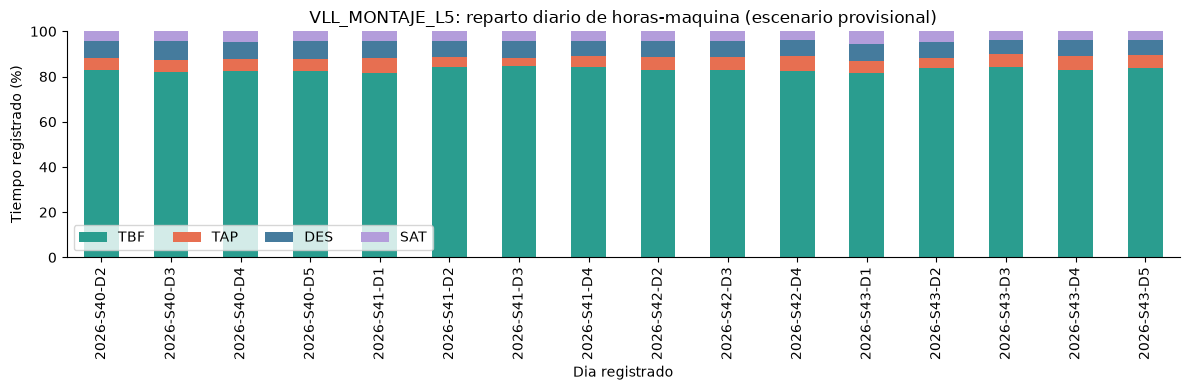

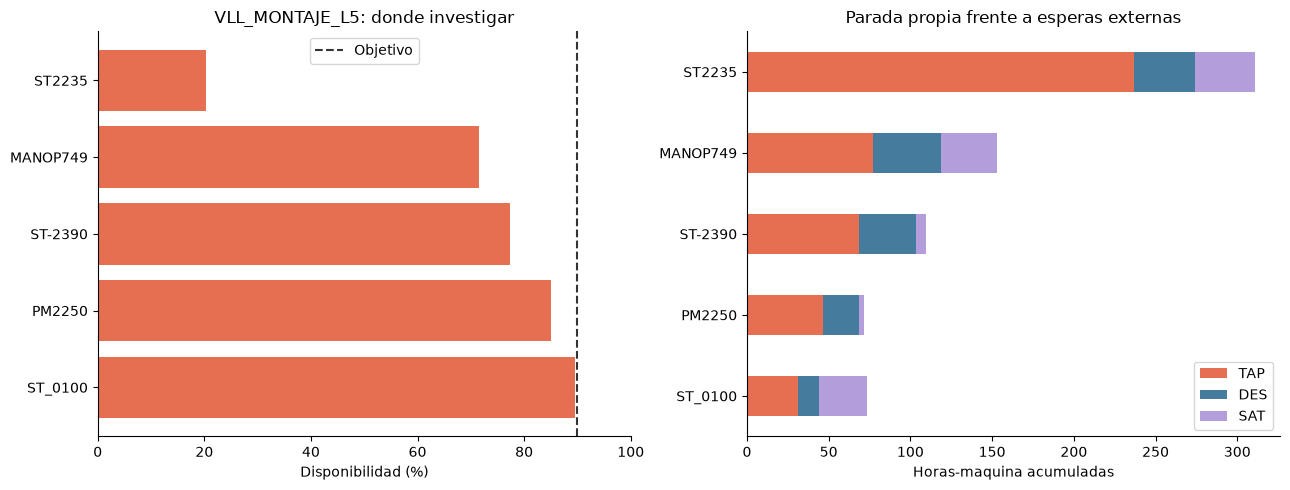

In [7]:
# Cada linea se compara por separado; la ordenacion no se usa como conexion causal.
for line, line_data in working.groupby('Linea'):
    daily = line_data.groupby(['Year', 'Week', 'Jour'])[TIMES].sum()
    shares = daily.div(daily.sum(axis=1).where(lambda s: s.gt(0)), axis=0) * 100
    shares.index = [f'{year}-S{week}-D{day}' for year, week, day in shares.index]
    ax = shares.plot.bar(stacked=True, color=[COLORS[c] for c in TIMES], figsize=(12, 4))
    ax.set(title=f'{line}: reparto diario de horas-maquina (escenario provisional)',
           xlabel='Dia registrado', ylabel='Tiempo registrado (%)', ylim=(0, 100))
    ax.legend(ncol=4)
    plt.tight_layout()
    plt.show()
    # Son horas-maquina; no horas perdidas de produccion final ni piezas de linea.
    top = priorities.loc[priorities.Linea.eq(line)].head(TOP_N).sort_values('availability_pct', ascending=False)
    if not top.empty:
        fig, axes = plt.subplots(1, 2, figsize=(13, 5))
        axes[0].barh(top.Operacion, top.availability_pct, color=COLORS['TAP'])
        axes[0].axvline(AVAILABILITY_TARGET, color='#333333', linestyle='--', label='Objetivo')
        axes[0].set(xlim=(0, 100), xlabel='Disponibilidad (%)', title=f'{line}: donde investigar')
        axes[0].legend()
        top.set_index('Operacion')[['TAP', 'DES', 'SAT']].plot.barh(stacked=True, ax=axes[1], color=[COLORS[c] for c in ['TAP', 'DES', 'SAT']])
        axes[1].set(xlabel='Horas-maquina acumuladas', ylabel='', title='Parada propia frente a esperas externas')
        plt.tight_layout()
        plt.show()

## 5. Recurrencia y posibles interrupciones breves

La recurrencia se compara en las semanas con datos, usando el escenario sin cierres
sospechosos. Una semana con menos dias no se compara mediante horas absolutas sin
mostrar la exposicion. El mapa usa disponibilidad, e indica dias observados / esperados.

Las microparadas solo se pueden confirmar con eventos y duraciones individuales.
Usamos frecuencia alta (cuartil superior de cada linea) y media menor al umbral
configurado como senal exploratoria. Si TAP y NAP son incompatibles, no calculamos
esa media. Una media baja puede ocultar una mezcla de averias largas y paradas cortas.

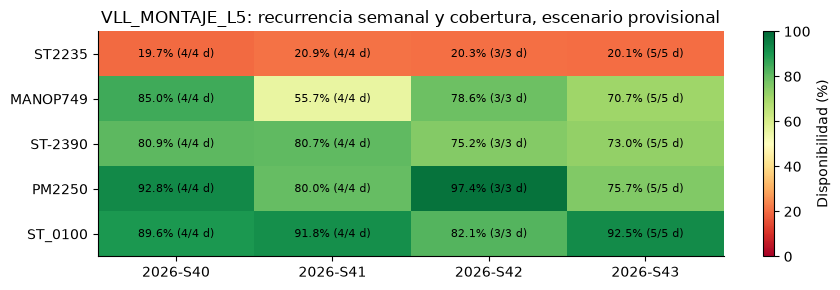

,Linea,Operacion,NAP,TAP,own_stop_rate,mean_stop_seconds
0,VLL_MONTAJE_L5,MANOP749,8376,77.28,571.31,33.21
10,VLL_MONTAJE_L5,PM2110,1817,4.22,76.07,8.36
11,VLL_MONTAJE_L5,PM2120,2644,16.66,108.60,22.68
13,VLL_MONTAJE_L5,PM2140,2126,5.10,86.81,8.64
15,VLL_MONTAJE_L5,PM2180,2357,3.75,96.23,5.73
19,VLL_MONTAJE_L5,PM2240,1401,5.27,56.97,13.54
23,VLL_MONTAJE_L5,PM_0090,5252,10.68,211.31,7.32
24,VLL_MONTAJE_L5,PM_0110,4130,8.80,166.65,7.67
26,VLL_MONTAJE_L5,PM_2260,2639,5.01,107.32,6.83
44,VLL_MONTAJE_L5,ST-0830,1613,4.57,65.94,10.20


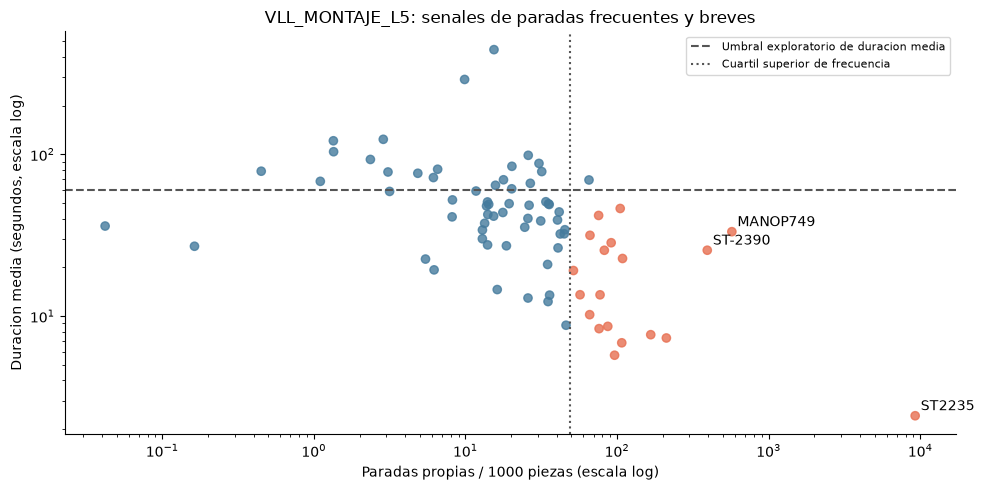

In [8]:
week_expected = working[DAY_KEYS].drop_duplicates().groupby(['Linea', 'Year', 'Week']).size().rename('expected_week_days').reset_index()
if weekly.empty:
    weekly['expected_week_days'] = pd.Series(dtype='int64')
else:
    weekly = weekly.merge(week_expected, on=['Linea', 'Year', 'Week'], validate='many_to_one')
for line, selected in priorities.groupby('Linea'):
    labels = selected.head(TOP_N).Operacion.tolist()
    selected_weekly = weekly.loc[weekly.Linea.eq(line) & weekly.Operacion.isin(labels)]
    heat = selected_weekly.pivot(index='Operacion', columns=['Year', 'Week'], values='availability_pct').reindex(labels)
    if heat.empty:
        continue
    fig, ax = plt.subplots(figsize=(9, max(3, len(heat)*0.55)))
    image = ax.imshow(heat.to_numpy(dtype=float), cmap='RdYlGn', vmin=0, vmax=100, aspect='auto')
    ax.set_xticks(range(len(heat.columns)), [f'{year}-S{week}' for year, week in heat.columns])
    ax.set_yticks(range(len(heat)), heat.index)
    for i, operation in enumerate(heat.index):
        for j, (year, week) in enumerate(heat.columns):
            row = selected_weekly.loc[selected_weekly.Operacion.eq(operation) & selected_weekly.Year.eq(year) & selected_weekly.Week.eq(week)]
            value = heat.iloc[i, j]
            text = 'Sin datos'
            if not row.empty and pd.notna(value):
                r = row.iloc[0]
                text = f'{value:.1f}% ({int(r.observed_days)}/{int(r.expected_week_days)} d)'
            ax.text(j, i, text, ha='center', va='center', fontsize=8)
    ax.set_title(f'{line}: recurrencia semanal y cobertura, escenario provisional')
    fig.colorbar(image, ax=ax, label='Disponibilidad (%)')
    plt.tight_layout()
    plt.show()

stop_candidates = active.loc[active.NAP.gt(0) & active.mean_stop_seconds.gt(0)].copy()
stop_candidates['frequency_threshold'] = stop_candidates.groupby('Linea').own_stop_rate.transform(lambda s: s.quantile(0.75))
stop_candidates['short_frequent_signal'] = stop_candidates.own_stop_rate.ge(stop_candidates.frequency_threshold) & stop_candidates.mean_stop_seconds.lt(MICROSTOP_MEAN_SECONDS)
display(stop_candidates.loc[stop_candidates.short_frequent_signal, ['Linea', 'Operacion', 'NAP', 'TAP', 'own_stop_rate', 'mean_stop_seconds']].round(2))
for line, points in stop_candidates.groupby('Linea'):
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.scatter(points.own_stop_rate, points.mean_stop_seconds,
               c=np.where(points.short_frequent_signal, COLORS['TAP'], COLORS['DES']), alpha=0.8)
    ax.axhline(MICROSTOP_MEAN_SECONDS, linestyle='--', color='#555555', label='Umbral exploratorio de duracion media')
    ax.axvline(points.frequency_threshold.iloc[0], linestyle=':', color='#555555', label='Cuartil superior de frecuencia')
    for row in points.nlargest(3, 'own_stop_rate').itertuples():
        ax.annotate(row.Operacion, (row.own_stop_rate, row.mean_stop_seconds), xytext=(4, 4), textcoords='offset points')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set(title=f'{line}: senales de paradas frecuentes y breves',
           xlabel=f'Paradas propias / {STOP_RATE_BASE} piezas (escala log)',
           ylabel='Duracion media (segundos, escala log)')
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

## 6. Conclusiones que admite este analisis

1. **La planificacion define la exposicion al riesgo.** Un cierre registrado como TAP
   puede hacer parecer poco fiable a una maquina que no tenia que producir.
2. **Calidad y fiabilidad industrial son cuestiones distintas.** Un contador inconsistente
   necesita revision del dato; no es evidencia suficiente de una averia.
3. **Las perdidas propias y las esperas requieren actuaciones diferentes.** TAP orienta
   mantenimiento de la operacion; DES/SAT orientan investigacion de flujo y suministro.
4. **Frecuencia, duracion y recurrencia se complementan.** Muchas interrupciones breves
   y pocas averias largas pueden acumular el mismo TAP y necesitar soluciones diferentes.
5. **Los agregados identifican candidatos, no causas demostradas.** Las ramas paralelas,
   los buffers y el desfase temporal impiden atribuir propagacion usando solo el orden.
6. **Prevenir exige seguimiento.** Tras intervenir, comparar periodos con planificacion
   y mezcla de producto similares. Cuatro semanas no bastan para predecir fallos.

No se calcula un indice de culpa ni se equiparan horas-maquina con produccion final
recuperable. Tampoco se exige que todas las filas sumen 22 horas ni se borran todos
los registros sin funcionamiento.

In [9]:
print('RESUMEN DE LA EXPLORACION')
print(f'{len(raw_data)} registros originales; {len(clean)} utilizables; {len(quarantine)} apartados.')
print(f'{int(audit["identical_copies_removed"])} copias identicas retiradas sin sumar sus valores.')
print(f'{int(days.day_status.eq("sin_actividad_por_confirmar").sum())} dias-linea sin actividad por confirmar.')
print(f'{int(days.day_status.eq("cierre_confirmado").sum())} dias-linea con cierre confirmado por calendario.')
print(f'{len(active)} operaciones comparables y {len(priorities)} bajo el objetivo en el escenario provisional.')
print(f'{len(slow_cycles)} operaciones con ciclo superior al objetivo, sujeto a unidades y validez del contador.')
print(f'{int(stop_candidates.short_frequent_signal.sum())} senales exploratorias de interrupciones frecuentes y breves.')
print('Antes de decidir: confirmar calendario, actividad prevista por operacion, unidades y semantica de contadores.')

RESUMEN DE LA EXPLORACION
1820 registros originales; 1820 utilizables; 0 apartados.
0 copias identicas retiradas sin sumar sus valores.
4 dias-linea sin actividad por confirmar.
0 dias-linea con cierre confirmado por calendario.
84 operaciones comparables y 5 bajo el objetivo en el escenario provisional.
7 operaciones con ciclo superior al objetivo, sujeto a unidades y validez del contador.
19 senales exploratorias de interrupciones frecuentes y breves.
Antes de decidir: confirmar calendario, actividad prevista por operacion, unidades y semantica de contadores.


## Alcance y reutilizacion

Para otros datos, cambiar las rutas y los mapas de columnas; confirmar la granularidad
diaria, las unidades y el significado de los contadores; aportar calendario de fabrica;
y configurar objetivos adecuados a cada linea. Los valores 22 horas, 90 %, 80 cmin
y 60 segundos son parametros de este caso, no constantes universales.

La cobertura solo se puede evaluar contra un universo conocido: el calendario puede
revelar dias completamente ausentes; sin el, no sabemos si faltan jornadas enteras.
La configuracion describe operaciones posibles, no garantiza que todas tuvieran que
producir ese periodo. Si hay turnos, productos o ramas con objetivos distintos,
incorporar esas dimensiones antes de comparar.

Entrega minima futura: `cleaning.py` para preparar y auditar; `analysis.py` para
indicadores y graficas; este notebook para documentar decisiones. Sin interfaz.